## Setup & Load Model With Eager Attention Access

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

PHASE2_ROOT = Path.cwd().resolve().parent
if str(PHASE2_ROOT) not in sys.path:
    sys.path.insert(0, str(PHASE2_ROOT))

from src.clip_eval import DEFAULT_MODEL_NAME, build_genre_text_embeddings, get_device
from src.paths import FIGURES_DIR, PREDICTIONS_PARQUET, SELECTED_6_GENRES, ensure_dirs

ensure_dirs()
device = get_device()

# attn_implementation="eager" exposes all 12 ViT self-attention matrices (12 heads x 50 x 50 tokens)
processor = CLIPProcessor.from_pretrained(DEFAULT_MODEL_NAME)
model = CLIPModel.from_pretrained(
    DEFAULT_MODEL_NAME,
    attn_implementation="eager",
).to(device)
model.eval()

df = pd.read_parquet(PREDICTIONS_PARQUET)
df_6 = df[df["benchmark"] == "6genre_p1_exact"].reset_index(drop=True)
print(f"Loaded {DEFAULT_MODEL_NAME} on {device} | 6-genre rows: {len(df_6):,}")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Loaded openai/clip-vit-base-patch32 on mps | 6-genre rows: 3,000


## Mechanism 1: Text-Encoder Prototype Overlap (Why Genres Confuse CLIP)

Before looking at a single book cover, this measures how close the 6 genre text embeddings already sit in CLIP’s 512-D cosine space.

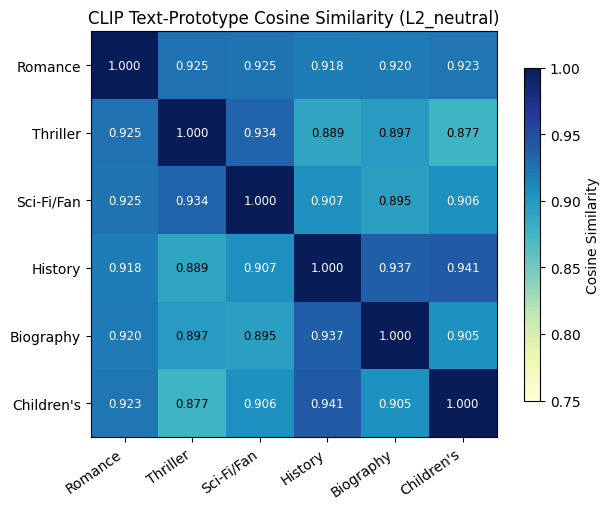

In [2]:
genre_embs = build_genre_text_embeddings(
    model=model,
    processor=processor,
    genres=SELECTED_6_GENRES,
    templates=["A book cover of a {genre} book."],
    device=device,
).cpu()

sim_matrix = (genre_embs @ genre_embs.T).numpy()
short_names = ["Romance", "Thriller", "Sci-Fi/Fan", "History", "Biography", "Children's"]

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(sim_matrix, cmap="YlGnBu", vmin=0.75, vmax=1.0)
ax.set_xticks(range(len(short_names)))
ax.set_xticklabels(short_names, rotation=35, ha="right")
ax.set_yticks(range(len(short_names)))
ax.set_yticklabels(short_names)
ax.set_title("CLIP Text-Prototype Cosine Similarity (L2_neutral)")

for i in range(len(short_names)):
    for j in range(len(short_names)):
        val = sim_matrix[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                color="white" if val > 0.90 else "black", fontsize=8.5)

fig.colorbar(im, ax=ax, shrink=0.82, label="Cosine Similarity")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig4_text_prototype_similarity.png", bbox_inches="tight")
plt.show()

## Mechanism 2: Latent Concept Probing (Why CLIP Associates Visual Stereotypes With Genres)

This projects both the genre text prototypes and your 3,000 covers onto explicit semantic concept directions inside CLIP’s shared embedding space—revealing which visual concepts are mathematically baked into each genre’s text vector.

,Dark / Ominous vs. Bright / Cheerful,Portrait / Human Face vs. Object / Scenery,Illustrated / Cartoon vs. Photographic,Heavy Typography vs. Minimal Text
Romance,0.0329,-0.1166,-0.1273,-0.0741
Thriller,0.1282,-0.1685,-0.1716,-0.0275
Sci-Fi/Fan,0.0783,-0.1476,-0.1098,-0.0804
History,0.0194,-0.1061,-0.1025,-0.1059
Biography,0.0201,-0.0826,-0.1362,-0.0554
Children's,-0.0302,-0.0684,-0.0239,-0.1202


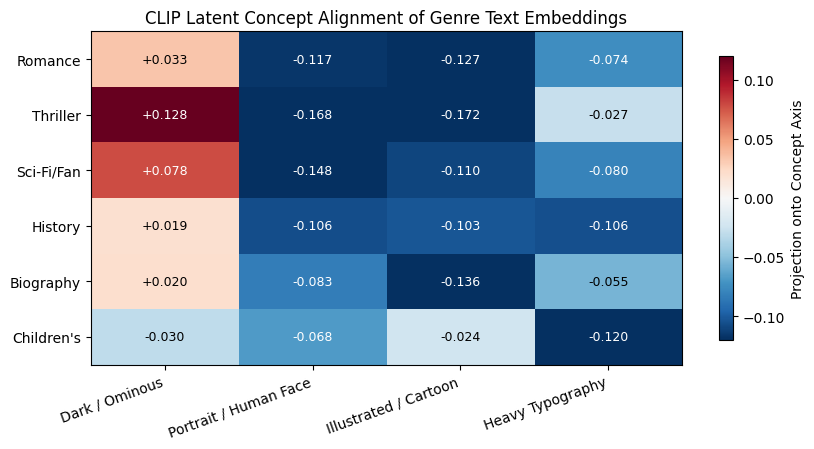

In [3]:
CONCEPT_PAIRS = {
    "Dark / Ominous vs. Bright / Cheerful": (
        "a dark, shadowy, ominous, gloomy book cover",
        "a bright, colorful, cheerful, sunny book cover",
    ),
    "Portrait / Human Face vs. Object / Scenery": (
        "a close-up portrait of a person's face on a book cover",
        "an empty landscape or object with no people on a book cover",
    ),
    "Illustrated / Cartoon vs. Photographic": (
        "a hand-drawn cartoon illustration on a book cover",
        "a realistic photograph on a book cover",
    ),
    "Heavy Typography vs. Minimal Text": (
        "a book cover dominated by large bold title typography",
        "a purely visual book cover artwork with almost no text",
    ),
}

concept_axes = {}
for concept_name, (pos_prompt, neg_prompt) in CONCEPT_PAIRS.items():
    inputs = processor(text=[pos_prompt, neg_prompt], return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        feats = F.normalize(model.get_text_features(**inputs), p=2, dim=-1).cpu()
    # Difference vector defines the semantic axis in CLIP's 512-D space
    axis = F.normalize(feats[0] - feats[1], p=2, dim=-1)
    concept_axes[concept_name] = axis

# Project each genre's text prototype onto the concept axes
alignment = pd.DataFrame(
    {
        cname: (genre_embs @ axis).numpy()
        for cname, axis in concept_axes.items()
    },
    index=short_names,
)
display(alignment.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
mat = alignment.to_numpy()
im = ax.imshow(mat, cmap="RdBu_r", vmin=-0.12, vmax=0.12, aspect="auto")
ax.set_xticks(range(len(alignment.columns)))
ax.set_xticklabels([c.split(" vs. ")[0] for c in alignment.columns], rotation=20, ha="right")
ax.set_yticks(range(len(short_names)))
ax.set_yticklabels(short_names)
ax.set_title("CLIP Latent Concept Alignment of Genre Text Embeddings")

for i in range(len(short_names)):
    for j in range(len(alignment.columns)):
        val = mat[i, j]
        ax.text(j, i, f"{val:+.3f}", ha="center", va="center",
                color="white" if abs(val) > 0.065 else "black", fontsize=9)

fig.colorbar(im, ax=ax, shrink=0.85, label="Projection onto Concept Axis")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig5_latent_concept_alignment.png", bbox_inches="tight")
plt.show()

## Mechanism 3: Patch-Level Attention-Gradient Saliency (7×7 ViT-B/32 Grid)

This looks inside ViT-B/32’s final transformer block to highlight which 32×32 image patches positively drive CLIP toward a specific genre—comparing (1) Original cover vs. True Genre, (2) Original cover vs. Wrong Stereotypical Genre, and (3) Text-Masked cover vs. Wrong Stereotypical Genre.

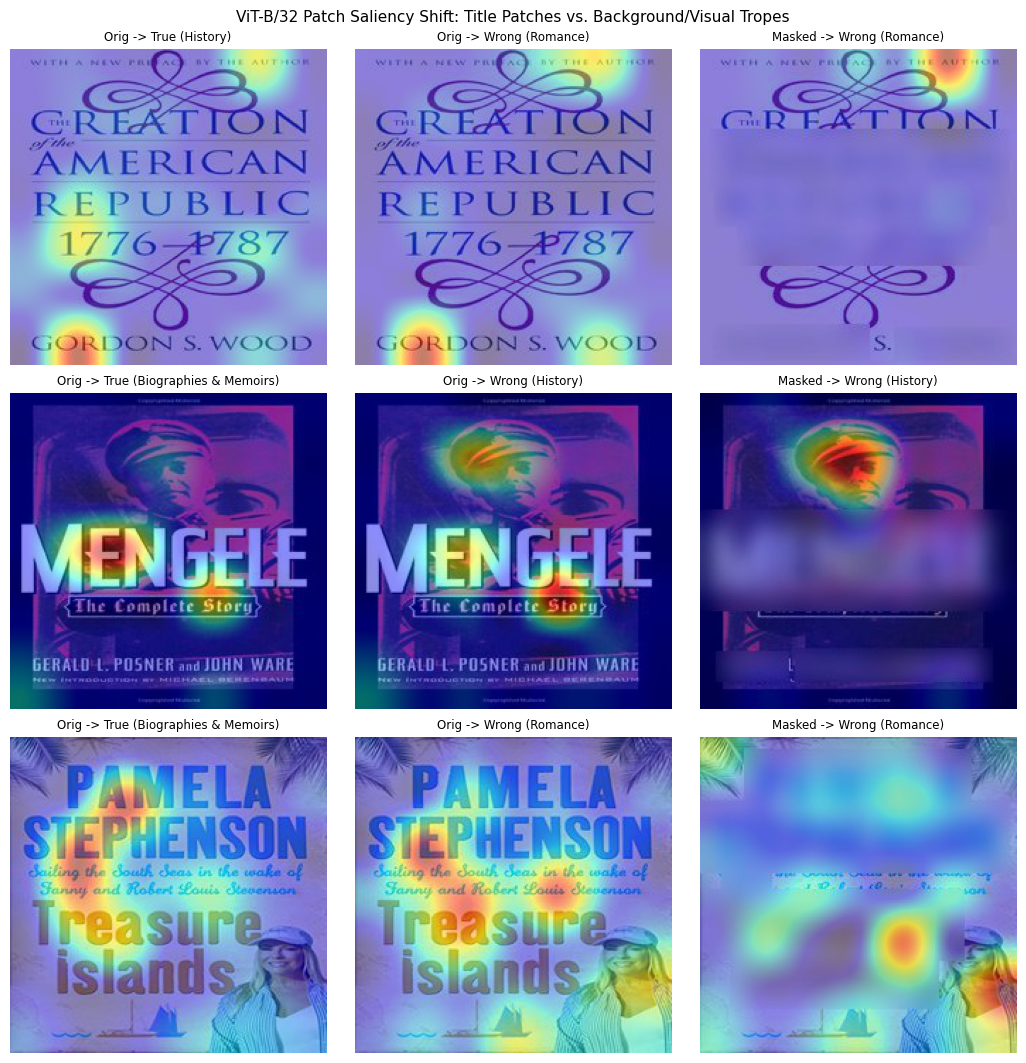

In [4]:
def compute_vit_patch_saliency(image_path: Path, text_embed: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:
    """Compute 7x7 ViT-B/32 Grad-CAM over [CLS]-to-patch attention weights for a target text vector."""
    with Image.open(image_path) as img:
        rgb = np.array(img.convert("RGB").resize((224, 224)))

    inputs = processor(images=Image.fromarray(rgb), return_tensors="pt").to(device)
    saved_attn = {}

    def hook_fn(module, inp, out):
        # out is (attn_output, attn_weights) in eager mode; shape: (1, 12, 50, 50)
        attn_weights = out[1]
        attn_weights.retain_grad()
        saved_attn["weights"] = attn_weights

    handle = model.vision_model.encoder.layers[-1].self_attn.register_forward_hook(hook_fn)
    try:
        model.zero_grad(set_to_none=True)
        vision_out = model.vision_model(pixel_values=inputs["pixel_values"], output_attentions=True)
        img_embed = F.normalize(model.visual_projection(vision_out.pooler_output), p=2, dim=-1)
        similarity = (img_embed @ text_embed.to(device).unsqueeze(-1)).squeeze()
        similarity.backward()

        attn = saved_attn["weights"]          # (1, 12, 50, 50)
        grad = attn.grad                      # (1, 12, 50, 50)
        # Focus on [CLS] token (index 0) attending to the 49 image patches (indices 1..49)
        cls_cam = (attn * grad).clamp(min=0).mean(dim=1)[0, 0, 1:]  # (49,)
        grid = cls_cam.detach().cpu().numpy().reshape(7, 7)
        grid = (grid - grid.min()) / (grid.max() - grid.min() + 1e-8)
    finally:
        handle.remove()

    heatmap = cv2.resize(grid, (224, 224), interpolation=cv2.INTER_CUBIC)
    return rgb, heatmap


# Pick 3 covers that flipped to a wrong genre when text was masked (or high-confidence errors)
flipped_cases = df_6[
    (df_6["orig_L2_neutral_pred"] == df_6["genre"])
    & (df_6["mask_L2_neutral_pred"] != df_6["genre"])
    & (df_6["text_area_ratio"] > 0.05)
].sample(n=3, random_state=42)

fig, axes = plt.subplots(len(flipped_cases), 3, figsize=(10.5, 3.6 * len(flipped_cases)))

for row_idx, (_, row) in enumerate(flipped_cases.iterrows()):
    true_idx = SELECTED_6_GENRES.index(row["genre"])
    wrong_genre = row["mask_L2_neutral_pred"]
    wrong_idx = SELECTED_6_GENRES.index(wrong_genre)

    rgb_orig, cam_true = compute_vit_patch_saliency(Path(row["image_path"]), genre_embs[true_idx])
    _, cam_wrong_orig = compute_vit_patch_saliency(Path(row["image_path"]), genre_embs[wrong_idx])
    rgb_mask, cam_wrong_mask = compute_vit_patch_saliency(Path(row["masked_image_path"]), genre_embs[wrong_idx])

    panels = [
        (rgb_orig, cam_true, f"Orig -> True ({row['genre'].split(',')[0]})"),
        (rgb_orig, cam_wrong_orig, f"Orig -> Wrong ({wrong_genre.split(',')[0]})"),
        (rgb_mask, cam_wrong_mask, f"Masked -> Wrong ({wrong_genre.split(',')[0]})"),
    ]
    for col_idx, (img_arr, heat, title) in enumerate(panels):
        ax = axes[row_idx, col_idx]
        ax.imshow(img_arr)
        ax.imshow(heat, cmap="jet", alpha=0.45)
        ax.set_title(title, fontsize=8.5)
        ax.axis("off")

plt.suptitle("ViT-B/32 Patch Saliency Shift: Title Patches vs. Background/Visual Tropes", fontsize=11)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig6_vit_patch_saliency.png", bbox_inches="tight")
plt.show()

## Group-Level Saliency Hypothesis Test

 Computes 7×7 ViT-B/32 attention-gradient saliency across a stratified sample of 300 covers (50 per genre) and compares center-vs.-border / title-region saliency concentration between Correct Predictions and Incorrect Predictions—directly fulfilling "compare saliency maps across correct and incorrect examples to understand whether this difference is consistent"

title_band_ratio  center_art_ratio
genre                        is_correct                                    
Biographies & Memoirs        False                  1.034             1.144
                             True                   1.035             1.123
Children's Books             False                  1.011             1.176
                             True                   1.150             0.980
History                      False                  1.060             1.118
                             True                   0.977             1.165
Mystery, Thriller & Suspense False                  1.203             0.903
                             True                   1.063             1.092
Romance                      False                  1.196             0.939
                             True                   1.095             1.026
Science Fiction & Fantasy    False                  1.125             1.024
                             True                   1.158             0.898

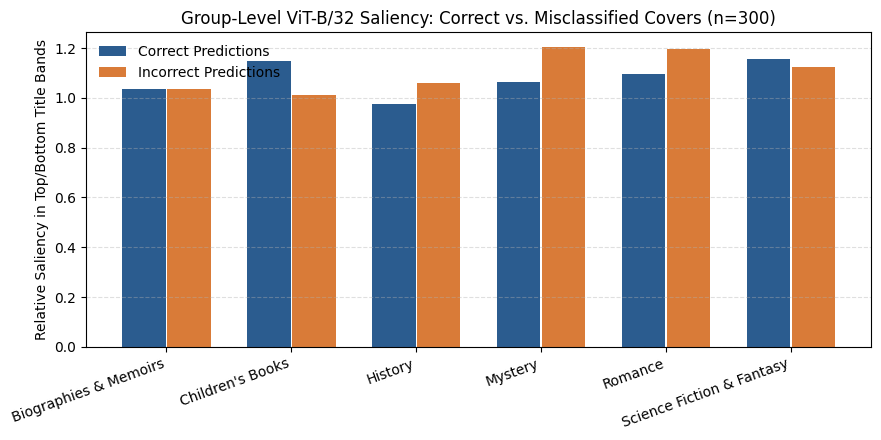

In [5]:

sample_300 = (
    df_6.groupby("genre", group_keys=False)
    .sample(n=50, random_state=42)
    .reset_index(drop=True)
)

saliency_records = []
for row in sample_300.itertuples():
    pred_genre = row.orig_L2_neutral_pred
    pred_idx = SELECTED_6_GENRES.index(pred_genre)
    _, heat = compute_vit_patch_saliency(Path(row.image_path), genre_embs[pred_idx])

    # Compare saliency mass in top/bottom title bands vs. central artwork
    top_bottom_saliency = np.concatenate([heat[:56, :], heat[168:, :]], axis=0).mean()
    center_saliency = heat[56:168, 32:192].mean()
    total_saliency = heat.mean() + 1e-8

    saliency_records.append(
        {
            "genre": row.genre,
            "is_correct": row.genre == pred_genre,
            "text_area_ratio": row.text_area_ratio,
            "title_band_ratio": float(top_bottom_saliency / total_saliency),
            "center_art_ratio": float(center_saliency / total_saliency),
        }
    )

df_sal_group = pd.DataFrame(saliency_records)
display(
    df_sal_group.groupby(["genre", "is_correct"])[["title_band_ratio", "center_art_ratio"]]
    .mean()
    .round(3)
)

# Plot group-level comparison
fig, ax = plt.subplots(figsize=(9, 4.5))
grouped = df_sal_group.groupby(["genre", "is_correct"])["title_band_ratio"].mean().unstack()
x = np.arange(len(grouped))
ax.bar(x - 0.18, grouped[True], width=0.35, label="Correct Predictions", color="#2b5c8f")
ax.bar(x + 0.18, grouped[False], width=0.35, label="Incorrect Predictions", color="#d97b38")
ax.set_xticks(x)
ax.set_xticklabels([g.split(",")[0] for g in grouped.index], rotation=20, ha="right")
ax.set_ylabel("Relative Saliency in Top/Bottom Title Bands")
ax.set_title("Group-Level ViT-B/32 Saliency: Correct vs. Misclassified Covers (n=300)")
ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig7_group_saliency_correct_vs_error.png", bbox_inches="tight")
plt.show()

## Representation Space Organization & k-NN Neighborhood Purity

 Measures 10-Nearest-Neighbor (k=10) genre consistency inside CLIP's 512-D image embedding space before and after text masking, and plots the 2D SVD projection of image + text prototypes to show how input groups cluster in the learned representation space.

,Orig 10-NN Purity (%),Masked 10-NN Purity (%),Purity Drop (pp)
Biographies & Memoirs,35.30,27.04,8.26
Children's Books,65.74,52.12,13.62
History,57.66,42.60,15.06
"Mystery, Thriller & Suspense",52.66,48.40,4.26
Romance,61.70,51.90,9.80
Science Fiction & Fantasy,58.40,48.84,9.56


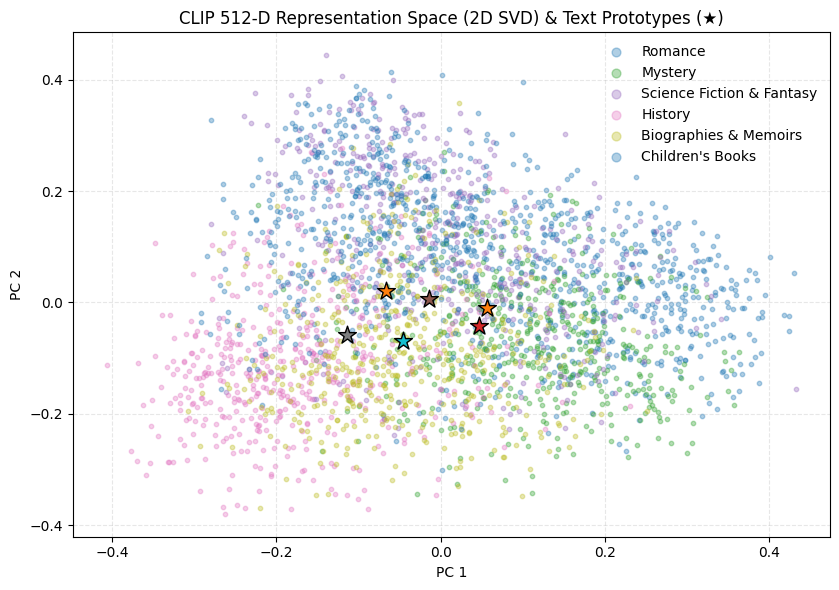

In [6]:
from src.clip_eval import encode_images

orig_embs_6 = encode_images(model, processor, [Path(p) for p in df_6["image_path"]], device=device, batch_size=64)
mask_embs_6 = encode_images(model, processor, [Path(p) for p in df_6["masked_image_path"]], device=device, batch_size=64)
labels_6 = df_6["genre"].to_numpy()

def knn_genre_purity(embs: torch.Tensor, labels: np.ndarray, k: int = 10) -> pd.Series:
    sim = embs @ embs.T
    sim.fill_diagonal_(-1.0)
    nn_idx = torch.topk(sim, k=k, dim=-1).indices.numpy()
    matches = (labels[nn_idx] == labels[:, None]).mean(axis=1)
    return pd.Series(matches).groupby(labels).mean() * 100

df_knn = pd.DataFrame(
    {
        "Orig 10-NN Purity (%)": knn_genre_purity(orig_embs_6, labels_6, k=10),
        "Masked 10-NN Purity (%)": knn_genre_purity(mask_embs_6, labels_6, k=10),
    }
).round(2)
df_knn["Purity Drop (pp)"] = (df_knn["Orig 10-NN Purity (%)"] - df_knn["Masked 10-NN Purity (%)"]).round(2)
display(df_knn)

# 2D SVD projection of CLIP image embeddings + genre text prototypes
centered = orig_embs_6 - orig_embs_6.mean(dim=0, keepdim=True)
_, _, Vt = torch.linalg.svd(centered, full_matrices=False)
proj_2d = (centered @ Vt[:2].T).numpy()
text_2d = ((genre_embs - orig_embs_6.mean(dim=0, keepdim=True)) @ Vt[:2].T).numpy()

fig, ax = plt.subplots(figsize=(8.5, 6))
for idx, genre in enumerate(SELECTED_6_GENRES):
    mask = labels_6 == genre
    ax.scatter(proj_2d[mask, 0], proj_2d[mask, 1], s=10, alpha=0.35, label=genre.split(",")[0])
    ax.scatter(text_2d[idx, 0], text_2d[idx, 1], s=180, marker="*", edgecolor="black", zorder=5)

ax.set_title("CLIP 512-D Representation Space (2D SVD) & Text Prototypes (★)")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.legend(frameon=False, markerscale=2)
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "fig8_representation_space_knn.png", bbox_inches="tight")
plt.show()